In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from scipy.integrate import solve_ivp


## RAMZI MODEL

RAMZI é composto por um micro-ring resonator (MRR) e MZI em série. Podemos escrever a dinâmica do (MRR) com a amplitude de luz, **$a$**, e a densidade de portadores **$N_c$**:

\begin{equation}
\frac{da}{dt} = - \left(j\Delta\omega + \gamma_L\right)a - j\eta_{fc}N_{c}a - j\mu\sqrt{P_{in}}
\end{equation}

\begin{equation}
\frac{dN_c}{dt} + \frac{N_c}{\tau_{fc}} = \xi |a|^4
\end{equation}




In [2]:
# ==========================================
# Exemplo Típico de Si-Photonics
# ==========================================
delta_omega = 2 * np.pi * 5e9  # Detuning da frequência (rad/s)
gamma_L = 1e10                # Taxa de perda linear (1/s)
eta_fc = 1e-12                # Coeficiente do efeito de portadores livres (FCD)
tau_fc = 1e-9                 # Tempo de vida dos portadores livres (s)
xi = 1e30                     # Coeficiente de absorção de dois fótons (TPA)
mu = 1e5                      # Coeficiente de acoplamento do campo

P_in = 0.2e-3                   # Potência de entrada (Watts)

def dramzi_mrr_system(t, y,P_in):
    """
    y[0]: Parte real de 'a' (Re{a})
    y[1]: Parte imaginária de 'a' (Im{a})
    y[2]: Densidade de portadores livres 'Nc'
    """
    a_real, a_imag, Nc = y
    a = a_real + 1j * a_imag
    a_sq_mag = np.abs(a)**2

    da_dt = -(1j * delta_omega + gamma_L) * a - 1j * eta_fc * Nc * a - 1j * mu * np.sqrt(P_in)

    dNc_dt = -Nc / tau_fc + xi * (a_sq_mag**2)

    return [da_dt.real, da_dt.imag, dNc_dt]

# ==========================================
# Condições Iniciais e Resolução Numérica
# ==========================================
# Estado inicial no tempo t=0: 
# campo interno nulo e Nc=0 | y0 = [a_real, a_imag, Nc] 
y0 = [0.0, 0.0, 0.0]

# Intervalo de tempo da simulação (0 a 5 nanosegundos)
t_span = (0, 20e-9)
t_eval = np.linspace(t_span[0], t_span[1], 1000000)

sol = solve_ivp(lambda t,y: dramzi_mrr_system(t,y,P_in), t_span, y0, t_eval=t_eval, method='RK45')

# Extração dos resultados
t = sol.t
a_complex = sol.y[0] + 1j * sol.y[1]
Nc = sol.y[2]
print(sol.success)

# Energia armazenada no anel |a|^2
a_intensity = np.abs(a_complex)**2



True


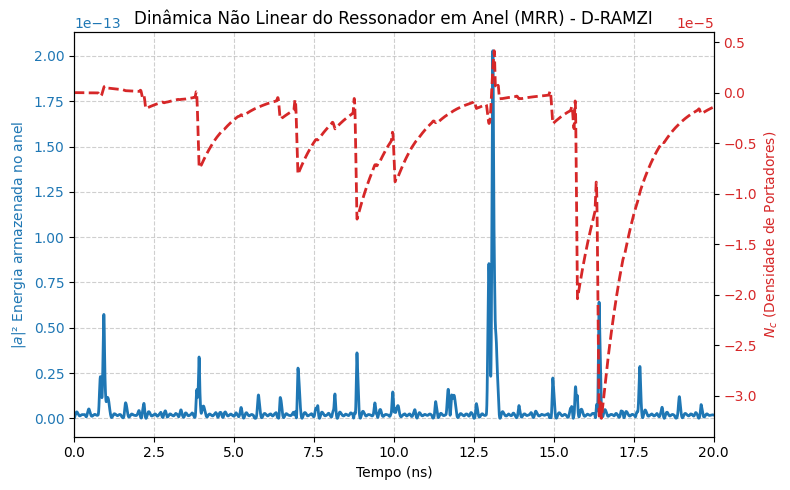

In [3]:
fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:blue'
ax1.set_xlabel('Tempo (ns)')
ax1.set_ylabel('$|a|²$ Energia armazenada no anel', color=color)
ax1.plot(t * 1e9, a_intensity, color=color, linewidth=2, label='|a|²')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('$N_c$ (Densidade de Portadores)', color=color)
ax2.plot(t * 1e9, Nc, color=color, linewidth=2, linestyle='--', label='N_c')
ax2.tick_params(axis='y', labelcolor=color)

plt.xlim(t_span[0]*1e9, t_span[1]*1e9)
plt.title('Dinâmica Não Linear do Ressonador em Anel (MRR) - D-RAMZI')
fig.tight_layout()
plt.show()

In [4]:
# gammaL = 1       # perda linear
# eta_fc = 3.0        # efeito dos portadores
# mu = 2.5            # acoplamento
# tau_fc = 5.0        # tempo de vida
# xi = 0.8            # geração de portadores
# delta_set = np.linspace(-4,1,9)

# # Potência de entrada (mW)
# Pin = np.linspace(0.0, 0.2, 1000)

# plt.figure(figsize=(8,6))

# for Delta in delta_set:

#     transmission = []

#     for P in Pin:

#         # Estado:
#         # y[0] = Re(a)
#         # y[1] = Im(a)
#         # y[2] = Nc

#         def model(t, y):

#             ar = y[0]
#             ai = y[1]
#             Nc = y[2]

#             a = ar + 1j*ai

#             da = -(1j*Delta + gammaL)*a \
#                  -1j*eta_fc*Nc*a \
#                  -1j*mu*np.sqrt(P)

#             dNc = xi*np.abs(a)**4 - Nc/tau_fc

#             return [
#                 np.real(da),
#                 np.imag(da),
#                 dNc
#             ]

#         sol = solve_ivp(model,[0,100],[0,0,0],method="RK45")

#         ar = sol.y[0,-1]
#         ai = sol.y[1,-1]

#         a = ar + 1j*ai

#         # transmissão aproximada
#         T = np.abs(a)**2

#         transmission.append(T)

#     transmission = np.array(transmission)
#     transmission /= transmission.max()

#     plt.plot(Pin/max(Pin), transmission, label= rf"$\Delta = {Delta:.2f}$")

# plt.xlabel("Input power (mW)")
# plt.ylabel("Normalized transmission")
# plt.title("MRR nonlinear transfer functions")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [5]:
# GammaL = np.linspace(0,0.2,9)       # perda linear
# eta_fc = 3.0        # efeito dos portadores
# mu = 2.5            # acoplamento
# tau_fc = 5.0        # tempo de vida
# xi = 0.8            # geração de portadores
# delta_set = 0

# # Potência de entrada (mW)
# Pin = np.linspace(0.0, 0.2, 1000)

# plt.figure(figsize=(8,6))

# for gammaL in GammaL:

#     transmission = []

#     for P in Pin:

#         # Estado:
#         # y[0] = Re(a)
#         # y[1] = Im(a)
#         # y[2] = Nc

#         def model(t, y):

#             ar = y[0]
#             ai = y[1]
#             Nc = y[2]

#             a = ar + 1j*ai

#             da = -(1j*Delta + gammaL)*a \
#                  -1j*eta_fc*Nc*a \
#                  -1j*mu*np.sqrt(P)

#             dNc = xi*np.abs(a)**4 - Nc/tau_fc

#             return [
#                 np.real(da),
#                 np.imag(da),
#                 dNc
#             ]

#         sol = solve_ivp(model,[0,100],[0,0,0],method="RK45")

#         ar = sol.y[0,-1]
#         ai = sol.y[1,-1]

#         a = ar + 1j*ai

#         # transmissão aproximada
#         T = np.abs(a)**2

#         transmission.append(T)

#     transmission = np.array(transmission)
#     transmission /= transmission.max()

#     plt.plot(Pin/max(Pin), transmission, label= rf"$\gamma_L = {gammaL:.2f}$")

# plt.xlabel("Input power (mW)")
# plt.ylabel("Normalized transmission")
# plt.title("MRR nonlinear transfer functions")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [6]:
# GammaL = 1      # perda linear
# Eta_fc = np.linspace(2,4,9)       # efeito dos portadores
# mu = 2.5            # acoplamento
# tau_fc = 5.0        # tempo de vida
# xi = 0.8            # geração de portadores
# delta_set = 0

# # Potência de entrada (mW)
# Pin = np.linspace(0.0, 0.2, 150)

# plt.figure(figsize=(8,6))

# for eta_fc in Eta_fc:

#     transmission = []

#     for P in Pin:

#         # Estado:
#         # y[0] = Re(a)
#         # y[1] = Im(a)
#         # y[2] = Nc

#         def model(t, y):

#             ar = y[0]
#             ai = y[1]
#             Nc = y[2]

#             a = ar + 1j*ai

#             da = -(1j*Delta + gammaL)*a \
#                  -1j*eta_fc*Nc*a \
#                  -1j*mu*np.sqrt(P)

#             dNc = xi*np.abs(a)**4 - Nc/tau_fc

#             return [
#                 np.real(da),
#                 np.imag(da),
#                 dNc
#             ]

#         sol = solve_ivp(model,[0,100],[0,0,0],method="RK45")

#         ar = sol.y[0,-1]
#         ai = sol.y[1,-1]

#         a = ar + 1j*ai

#         # transmissão aproximada
#         T = np.abs(a)**2

#         transmission.append(T)

#     transmission = np.array(transmission)
#     transmission /= transmission.max()

#     plt.plot(Pin/max(Pin), transmission, label= rf"$\eta_{{fc}} = {eta_fc:.2f}$")

# plt.xlabel("Input power (mW)")
# plt.ylabel("Normalized transmission")
# plt.title("MRR nonlinear transfer functions")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [7]:
# GammaL = 1      # perda linear
# Eta_fc = 3       # efeito dos portadores
# Mu = np.linspace(1.5,3.5,9)            # acoplamento
# tau_fc = 5.0        # tempo de vida
# xi = 0.8            # geração de portadores
# delta_set = 0

# # Potência de entrada (mW)
# Pin = np.linspace(0.0, 0.2, 150)

# plt.figure(figsize=(8,6))

# for mu in Mu:

#     transmission = []

#     for P in Pin:

#         # Estado:
#         # y[0] = Re(a)
#         # y[1] = Im(a)
#         # y[2] = Nc

#         def model(t, y):

#             ar = y[0]
#             ai = y[1]
#             Nc = y[2]

#             a = ar + 1j*ai

#             da = -(1j*Delta + gammaL)*a \
#                  -1j*eta_fc*Nc*a \
#                  -1j*mu*np.sqrt(P)

#             dNc = xi*np.abs(a)**4 - Nc/tau_fc

#             return [
#                 np.real(da),
#                 np.imag(da),
#                 dNc
#             ]

#         sol = solve_ivp(model,[0,100],[0,0,0],method="RK45")

#         ar = sol.y[0,-1]
#         ai = sol.y[1,-1]

#         a = ar + 1j*ai

#         # transmissão aproximada
#         T = np.abs(a)**2

#         transmission.append(T)

#     transmission = np.array(transmission)
#     transmission /= transmission.max()

#     plt.plot(Pin/max(Pin), transmission, label= rf"$\mu = {mu:.2f}$")

# plt.xlabel("Input power (mW)")
# plt.ylabel("Normalized transmission")
# plt.title("MRR nonlinear transfer functions")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [8]:
# GammaL = 1      # perda linear
# Eta_fc = 3       # efeito dos portadores
# Mu = 2.5           # acoplamento
# Tau_fc = np.linspace(4,6,9)       # tempo de vida
# xi = 0.8            # geração de portadores
# delta_set = 0

# # Potência de entrada (mW)
# Pin = np.linspace(0.0, 0.2, 150)

# plt.figure(figsize=(8,6))

# for tau_fc in Tau_fc:

#     transmission = []

#     for P in Pin:

#         # Estado:
#         # y[0] = Re(a)
#         # y[1] = Im(a)
#         # y[2] = Nc

#         def model(t, y):

#             ar = y[0]
#             ai = y[1]
#             Nc = y[2]

#             a = ar + 1j*ai

#             da = -(1j*Delta + gammaL)*a \
#                  -1j*eta_fc*Nc*a \
#                  -1j*mu*np.sqrt(P)

#             dNc = xi*np.abs(a)**4 - Nc/tau_fc

#             return [
#                 np.real(da),
#                 np.imag(da),
#                 dNc
#             ]

#         sol = solve_ivp(model,[0,100],[0,0,0],method="RK45")

#         ar = sol.y[0,-1]
#         ai = sol.y[1,-1]

#         a = ar + 1j*ai

#         # transmissão aproximada
#         T = np.abs(a)**2

#         transmission.append(T)

#     transmission = np.array(transmission)
#     transmission /= transmission.max()

#     plt.plot(Pin/max(Pin), transmission, label= rf"$\tau_{{fc}} = {tau_fc:.2f}$")

# plt.xlabel("Input power (mW)")
# plt.ylabel("Normalized transmission")
# plt.title("MRR nonlinear transfer functions")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [9]:
# GammaL = 1      # perda linear
# Eta_fc = 3       # efeito dos portadores
# Mu = 2.5           # acoplamento
# Tau_fc = 5       # tempo de vida
# Xi = np.linspace(0.1,1,9)            # geração de portadores
# delta_set = 0

# # Potência de entrada (mW)
# Pin = np.linspace(0.0, 0.2, 150)

# plt.figure(figsize=(8,6))

# for xi in Xi:

#     transmission = []

#     for P in Pin:

#         # Estado:
#         # y[0] = Re(a)
#         # y[1] = Im(a)
#         # y[2] = Nc

#         def model(t, y):

#             ar = y[0]
#             ai = y[1]
#             Nc = y[2]

#             a = ar + 1j*ai

#             da = -(1j*Delta + gammaL)*a \
#                  -1j*eta_fc*Nc*a \
#                  -1j*mu*np.sqrt(P)

#             dNc = xi*np.abs(a)**4 - Nc/tau_fc

#             return [
#                 np.real(da),
#                 np.imag(da),
#                 dNc
#             ]

#         sol = solve_ivp(model,[0,100],[0,0,0],method="RK45")

#         ar = sol.y[0,-1]
#         ai = sol.y[1,-1]

#         a = ar + 1j*ai

#         # transmissão aproximada
#         T = np.abs(a)**2

#         transmission.append(T)

#     transmission = np.array(transmission)
#     transmission /= transmission.max()

#     plt.plot(Pin/max(Pin), transmission, label= rf"$\xi = {xi:.2f}$")

# plt.xlabel("Input power (mW)")
# plt.ylabel("Normalized transmission")
# plt.title("MRR nonlinear transfer functions")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [10]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.integrate import solve_ivp

# # ============================================================
# # Parâmetros
# # ============================================================

# gammaL = 1.0
# eta_fc = 3.0
# mu = 2.5
# tau_fc = 5.0
# xi = 0.8

# # coeficientes do acoplador do anel
# t = 0.90          # transmissão
# k = np.sqrt(1-t**2)

# Pin = np.linspace(0,0.2,300)

# Delta = 0

# Delta_phi = np.linspace(0,2*np.pi,10)

# # ============================================================
# # Resolve o MRR
# # ============================================================

# fields = []

# for P in Pin:

#     def model(ti,y):

#         ar,ai,Nc = y

#         a = ar + 1j*ai

#         da = -(1j*Delta + gammaL)*a \
#              -1j*eta_fc*Nc*a \
#              -1j*mu*np.sqrt(P)

#         dNc = xi*np.abs(a)**4 - Nc/tau_fc

#         return [
#             np.real(da),
#             np.imag(da),
#             dNc
#         ]

#     sol = solve_ivp(
#         model,
#         [0,100],
#         [0,0,0]
#     )

#     ar,ai,Nc = sol.y[:,-1]

#     a = ar + 1j*ai

#     Ein = np.sqrt(P)

#     E_through = t*Ein - 1j*k*a

#     fields.append(E_through)

# fields = np.array(fields)

# # ============================================================
# # RAMZI
# # ============================================================

# plt.figure(figsize=(8,6))

# for phi in Delta_phi:

#     Ein = np.sqrt(Pin)

#     upper = fields

#     lower = Ein*np.exp(1j*phi)

#     Eout = (upper + lower)/np.sqrt(2)

#     Tout = np.abs(Eout)**2

#     plt.plot(
#         Pin,
#         Tout,
#         label=rf"$\Delta\phi={phi/np.pi:.2f}\pi$"
#     )

# plt.xlabel("Input power (mW)")
# plt.ylabel("Output power")
# plt.title("RAMZI transfer function")
# plt.grid(True)
# plt.legend()
# plt.show()

## FUNÇÕES DE TRANSFERÊNCIA

- **Directional Coupler (DC):**

Para o acoplador direcional (DC) temos:

$$
\begin{pmatrix}
A_o\\
B_o
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
r & -jt\\
-jt^* & r^*
\end{bmatrix}
}_{\text{Matriz de transferência}}
\begin{pmatrix}
A_i\\
B_i
\end{pmatrix}
$$

Se for um DC 3 dB, 50:50, $|r| = |t| = \frac{1}{\sqrt{2}}$

- **Waveguide (WVG):**

Para um waveguide de comprimento $l_0$ temos:

$$
\begin{pmatrix}
A_o
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
e^{-j\beta l_0}
\end{bmatrix}
}_{\text{Matriz de\\ transferência}}
\begin{pmatrix}
A_i
\end{pmatrix}
$$

- **Micro-Ring Resonator (MRR):**

Para um anel, apenas com throughtput port, com anel de comprimento $l_0$, temos:

$$
\begin{pmatrix}
A_o
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
\frac{r^* - a e^{-j\beta l_0}}{1 - ra e^{-j\beta l_0}}
\end{bmatrix}
}_{\text{Matriz de\\ transferência}}
\begin{pmatrix}
A_i
\end{pmatrix}
$$

- **Ring Resonator (RR):**

Para um anel, com throughput/drop port, com anel de comprimento $l_0$, temos:

$$
\begin{pmatrix}
A_{drop} \\
A_{troughput}
\end{pmatrix}
=
\underbrace{
\begin{bmatrix}
\frac{a(-t_1 t_2^* e^{j \beta l_0/2})}{e^{j\beta l_0 -r_2r_1}} & \frac{-r_1 + r_2^*e^{j\beta l_0}}{e^{j\beta l_0 -r_2r_1}} \\
\frac{ -r_2 + r_1^* e^{j \beta l_0}}{e^{j\beta l_0 -r_2r_1}} & \frac{-t_1^*t_2 e^{j\beta l_0/2}}{a(e^{j\beta l_0 -r_2r_1})}
\end{bmatrix}
}_{\text{Matriz de\\ transferência}}
\begin{pmatrix}
A_{i} \\
A_{add}
\end{pmatrix}
$$

In [11]:
def Beta_calc(ng, neff0,lambda0,lamb_vector):
    dneff_dlambda = (neff0 - ng)/lambda0
    neff = neff0 + dneff_dlambda*(lamb_vector - lambda0)
    Beta = 2*np.pi*neff/lamb_vector
    return Beta

def DC(r):
    t = np.sqrt(1-r**2)
    C = np.array([[r, -1j*t],
                  [-1j*np.conj(t), np.conj(r)]])
    return C

def ARMS_FOR_MZI(Beta, l0, delta_L):


    ARMS = np.zeros((len(Beta), 2, 2), dtype=complex)

    ARMS[:,0,0] = np.exp(-1j*Beta*(l0 + delta_L/2))
    ARMS[:,1,1] = np.exp(-1j*Beta*(l0 - delta_L/2))

    return ARMS

def MRR(beta, L, a, r):

    H = np.zeros((len(beta), 1, 1), dtype=complex)

    H[:,0,0] = (np.conj(r) - a*np.exp(-1j*beta*L)) / (1 - r*a*np.exp(-1j*beta*L))
    return H

def RR(beta, L, a, r1, r2):

    H = np.zeros((len(beta), 2, 2), dtype=complex)

    t1 = np.sqrt(1 - np.abs(r1)**2)
    t2 = np.sqrt(1 - np.abs(r2)**2)

    den = np.exp(1j*beta*L)-r1*r2
    H[:,0,0] = (-t1*np.conj(t2)*np.exp(1j*beta*L/2)*a)/den
    H[:,0,1] = (-r1+np.conj(r2)*np.exp(1j*beta*L)) / den
    H[:,1,0] = (np.conj(r1)*np.exp(1j*beta*L)-r2) / den
    H[:,1,1] = (-t2*np.conj(t1)*np.exp(1j*beta*L/2)) / den

    return H

def WVG(beta, L):

    H = np.zeros((len(beta), 1, 1), dtype=complex)

    H[:,0,0] = np.exp(-1j*beta*L)

    return H

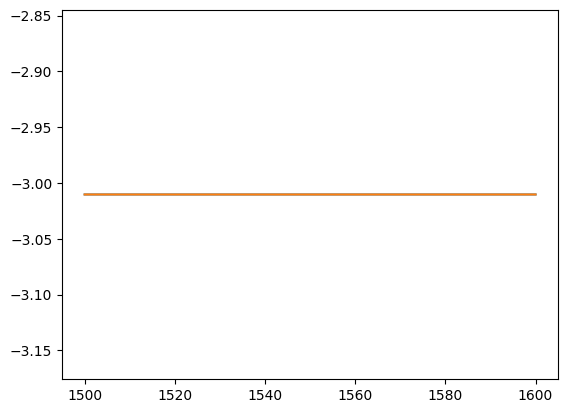

In [12]:
lamb = np.linspace(1500e-9,1600e-9,100000)

In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))
result = C @ In
Ao = result[0][0]*np.ones_like(lamb)
Bo = result[1][0]*np.ones_like(lamb)

T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)))

In [13]:
lamb = np.linspace(1500e-9,1600e-9,100000)

neff0 = 2.3537
ng = 2.3537
lambda0 = 1550e-9
FSR_nm = 20e-9
l0 = 300e-6
delta_L = (lambda0**2)/(ng*FSR_nm)

Beta = Beta_calc(ng, neff0, lambda0, lamb)

(1.0, -1.0)

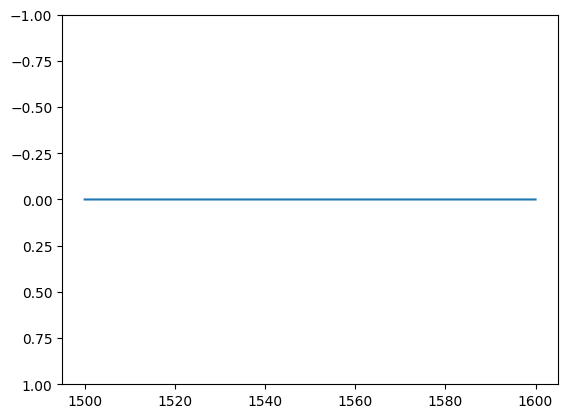

In [14]:
In = np.array([[1]])
wvg = WVG(Beta,L=l0)

wvg = wvg@In

Ao = wvg[:,0,0]

T5 = np.abs(Ao)**2

plt.plot(lamb*1e9,10*np.log10(T5))
plt.ylim(1,-1)


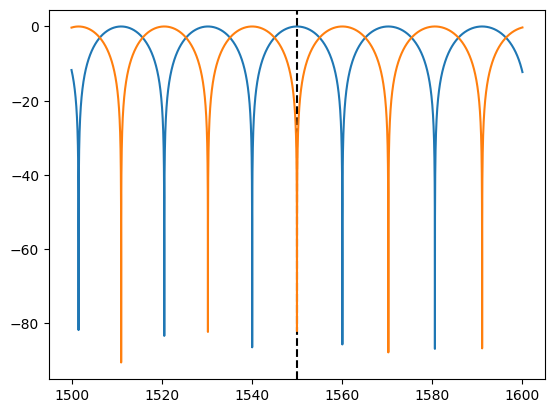

In [15]:
In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))
ARMS = ARMS_FOR_MZI(Beta,l0,delta_L)
MZI = C @ ARMS @ C @ In

Ao = MZI[:,0,0]
Bo = MZI[:,1,0]
T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)))



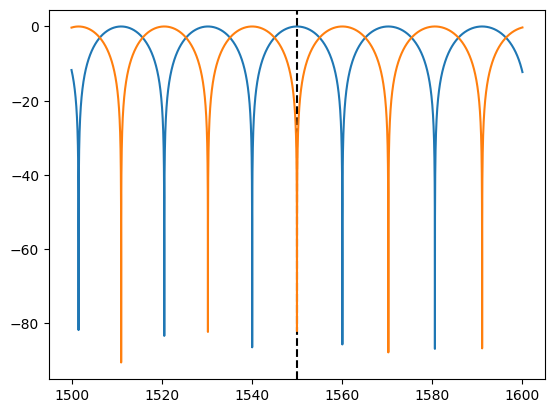

In [16]:
In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))

WVG1 = WVG(Beta,l0 + delta_L/2)
WVG2 = WVG(Beta,l0 - delta_L/2)
ARMS = np.zeros((len(Beta), 2, 2), dtype=complex)
ARMS[:,0,0] = WVG1[:,0,0]
ARMS[:,1,1] = WVG2[:,0,0]

MZI = C @ ARMS @ C @ In

Ao = MZI[:,0,0]
Bo = MZI[:,1,0]
T3 = np.abs(Ao)**2
T4 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(np.abs(T3)))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")
plt.plot(lamb*1e9,10*np.log10(np.abs(T4)))



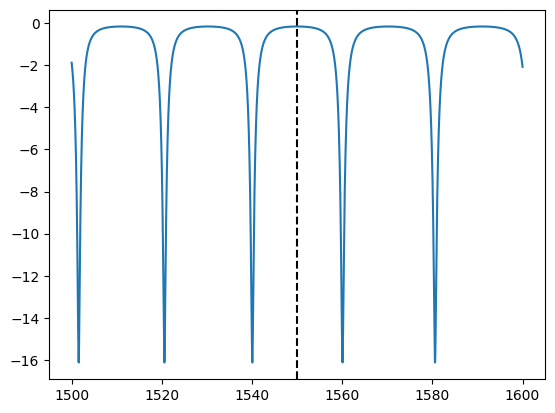

In [17]:
In = np.array([[1]])
r = 0.85
mrr = MRR(Beta,L=delta_L,a=0.8,r=r)

mrr = mrr@In

Ao = mrr[:,0,0]

T5 = np.abs(Ao)**2

plt.plot(lamb*1e9,10*np.log10(T5))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")

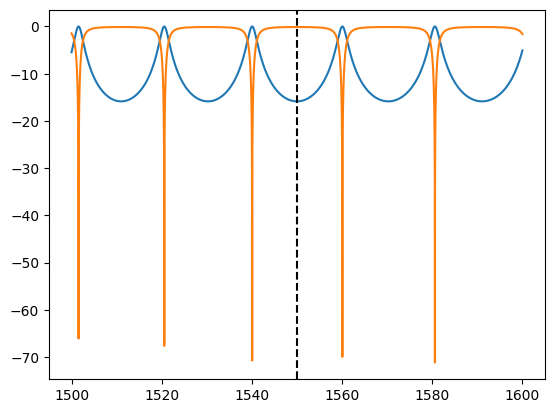

In [18]:
In = np.array([[1],[0]])

r1 = r2 = 0.85
rr = RR(Beta,L=delta_L,a=1,r1=r1,r2=r2)

rr = rr@In

Ao = rr[:,0,0]
Bo = rr[:,1,0]

T5 = np.abs(Ao)**2
T6 = np.abs(Bo)**2

plt.plot(lamb*1e9,10*np.log10(T5))
plt.plot(lamb*1e9,10*np.log10(T6))
plt.axvline(x=lambda0*1e9, ls = "--", c="k")

In [19]:
In = np.array([[1],[0]])

C = DC(1/np.sqrt(2))
first = C @ In

mrr = MRR(Beta,L=delta_L,a=0.8,r=1/np.sqrt(2))
wvg = WVG(Beta,L=delta_L)

A1 = np.ones((len(Beta),1,1),dtype=complex)*first[0,0]
B1 = np.ones((len(Beta),1,1),dtype=complex)*first[1,0]

A2 = mrr@A1
B2 = wvg@B1

aux1 = np.ones((len(Beta),2,1),dtype=complex)
aux1[:,0,0] = A2[:,0,0]
aux1[:,1,0] = B2[:,0,0]

Out = C @ aux1

Ao = Out[:,0,0]
Bo = Out[:,1,0]

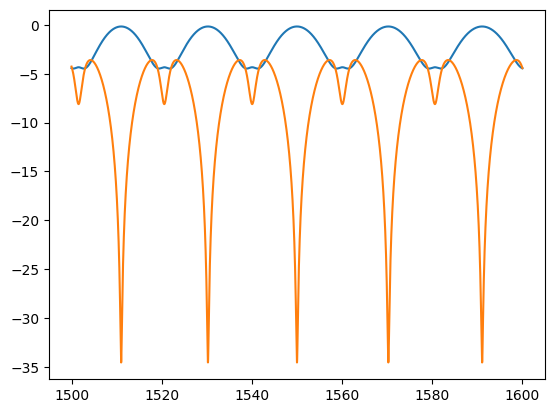

In [20]:
plt.plot(lamb*1e9,10*np.log10(np.abs(Ao)**2))
plt.plot(lamb*1e9,10*np.log10(np.abs(Bo)**2))